In [4]:
import pandas as pd

# 1. Muat dataset 
df_clean = pd.read_csv('top_insta_influencers_data[1].csv') 

# ====================================================
# [SOLUSI] PEMBERSIHAN DATA SEBELUM PERHITUNGAN
# ====================================================
# 1. Hilangkan simbol '%' dan ubah menjadi float (angka desimal)
df_clean['60_day_eng_rate'] = df_clean['60_day_eng_rate'].astype(str).str.replace('%', '').astype(float)

# (Opsional) Pastikan kolom angka lainnya tidak terbaca sebagai string/teks
df_clean['followers'] = pd.to_numeric(df_clean['followers'], errors='coerce')
df_clean['influence_score'] = pd.to_numeric(df_clean['influence_score'], errors='coerce')

# ====================================================
# 1. KEY PERFORMANCE INDICATORS (KPI)
# ====================================================
total_influencers = len(df_clean)
total_followers_sum = df_clean['followers'].sum()
avg_influence = df_clean['influence_score'].mean()
avg_engagement = df_clean['60_day_eng_rate'].mean()

print("========================================")
print("       KEY PERFORMANCE INDICATORS       ")
print("========================================")
print(f"• Total Akun Influencer Teratas : {total_influencers:,} akun")
print(f"• Total Akumulasi Followers     : {total_followers_sum:,.0f} pengikut")
print(f"• Rata-rata Skor Pengaruh       : {avg_influence:.2f} / 100")
print(f"• Rata-rata Engagement Rate     : {avg_engagement:.2f}%")
print("========================================")

       KEY PERFORMANCE INDICATORS       
• Total Akun Influencer Teratas : 200 akun
• Total Akumulasi Followers     : 0 pengikut
• Rata-rata Skor Pengaruh       : 81.82 / 100
• Rata-rata Engagement Rate     : 1.90%


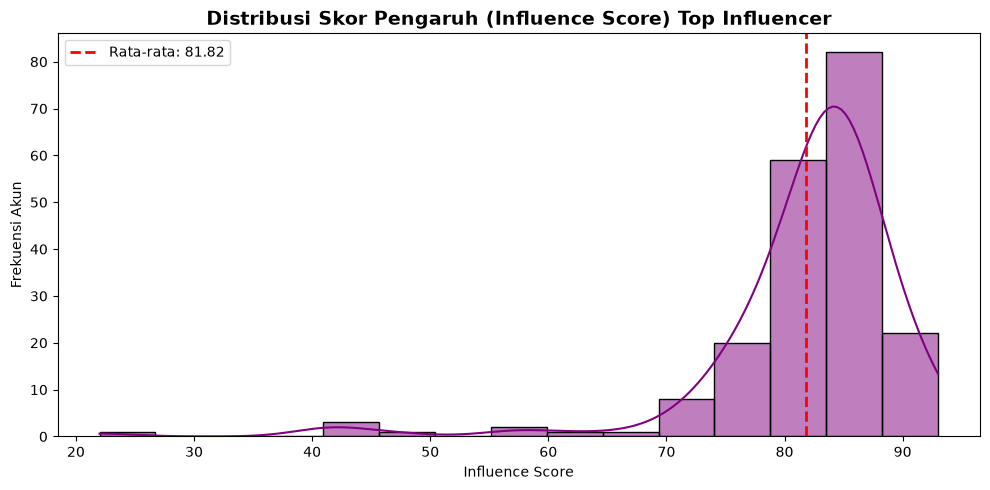

In [6]:
# Tambahkan dua baris import ini di bagian paling atas
import matplotlib.pyplot as plt
import seaborn as sns

# ====================================================
# 2. VISUALISASI 1: Distribusi Skor Pengaruh (Influence Score)
# ====================================================
plt.figure(figsize=(10, 5))
sns.histplot(df_clean['influence_score'], bins=15, kde=True, color='purple')
plt.title('Distribusi Skor Pengaruh (Influence Score) Top Influencer', fontsize=14, fontweight='bold')
plt.xlabel('Influence Score')
plt.ylabel('Frekuensi Akun')
plt.axvline(avg_influence, color='red', linestyle='--', linewidth=2, label=f'Rata-rata: {avg_influence:.2f}')
plt.legend()
plt.tight_layout()
plt.show()

C:\Users\Ibnu Syina\AppData\Local\Temp\ipykernel_13612\470967600.py:19: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title='Influence Score', bbox_to_anchor=(1.05, 1), loc='upper left')


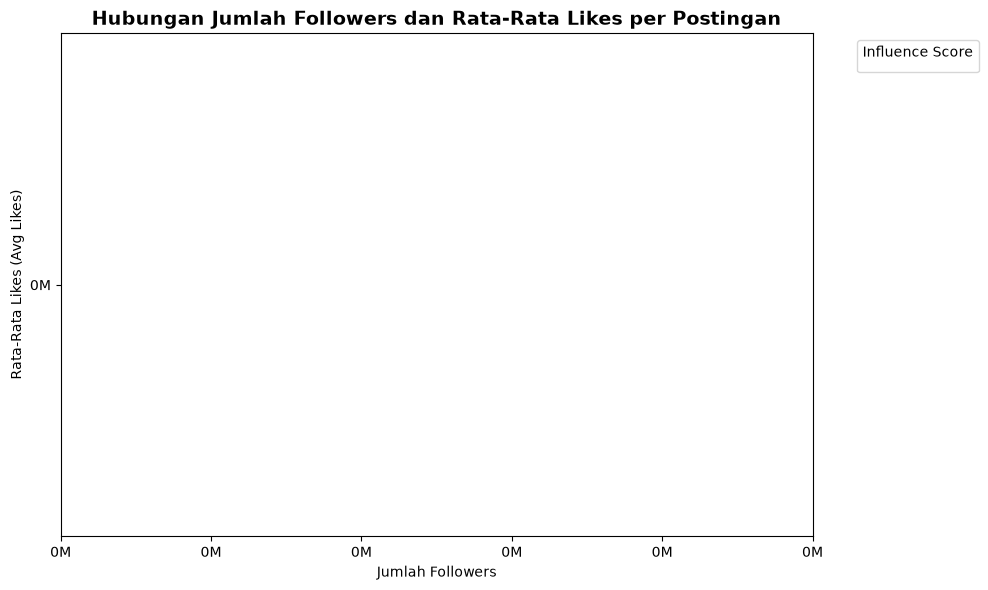

In [7]:
# ====================================================
# 3. VISUALISASI 2: Hubungan Followers vs Avg Likes (Scatter Plot)
# ====================================================
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df_clean, 
    x='followers', 
    y='avg_likes', 
    hue='influence_score', 
    palette='viridis', 
    s=80, 
    alpha=0.8
)
plt.title('Hubungan Jumlah Followers dan Rata-Rata Likes per Postingan', fontsize=14, fontweight='bold')
plt.xlabel('Jumlah Followers')
plt.ylabel('Rata-Rata Likes (Avg Likes)')
plt.gca().xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{int(x*1e-6)}M'))
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{int(x*1e-6)}M'))
plt.legend(title='Influence Score', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

C:\Users\Ibnu Syina\AppData\Local\Temp\ipykernel_13612\1093316812.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_countries_eng, x='60_day_eng_rate', y='country', palette='crest')


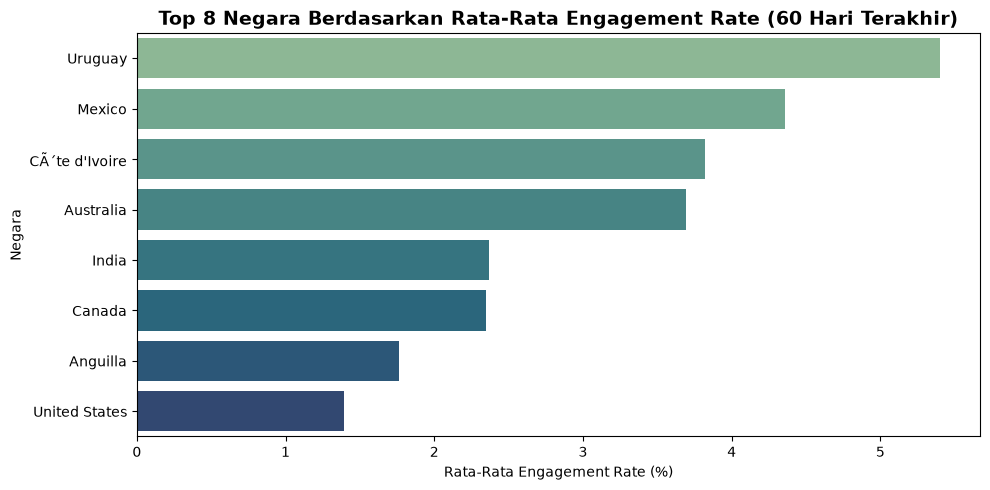

In [8]:
# ====================================================
# 4. VISUALISASI 3: Rata-Rata Engagement Rate Berdasarkan Negara
# ====================================================
top_countries_eng = df_clean.groupby('country')['60_day_eng_rate'].mean().reset_index()
top_countries_eng = top_countries_eng.sort_values(by='60_day_eng_rate', ascending=False).head(8)

plt.figure(figsize=(10, 5))
sns.barplot(data=top_countries_eng, x='60_day_eng_rate', y='country', palette='crest')
plt.title('Top 8 Negara Berdasarkan Rata-Rata Engagement Rate (60 Hari Terakhir)', fontsize=14, fontweight='bold')
plt.xlabel('Rata-Rata Engagement Rate (%)')
plt.ylabel('Negara')
plt.tight_layout()
plt.show()

In [10]:
# ## Visualisasi, KPI, dan Analisis Insight
#
# 1. *Key Performance Indicators (KPI):* Memantau total jangkauan followers, rata-rata skor pengaruh, dan tingkat engagement rata-rata dari 200 akun teratas.
# 2. *Visualisasi Data:*
#    - *Distribusi Influence Score:* Melihat sebaran tingkat pengaruh akun.
#    - *Followers vs Avg Likes:* Menganalisis korelasi antara skala pengikut dan interaksi nyata.
#    - *Engagement Rate per Negara:* Menilai performa keaktifan audiens berdasarkan wilayah geografis.
# 3. *Insight & Rekomendasi:* Panduan strategis bagi pemasar dalam memilih influencer yang tepat berdasarkan tujuan kampanye (awareness vs conversion).